# 09 — Per-Gameweek Point Buckets (current season, 2026/27)

A season total hides *shape*. Two 150-point midfielders can get there via steady 5s or via
a fistful of hauls between blanks. We bucket **every player-GW** of the current season into four
tiers and count how a player's season splits across them.

- **Data:** the official FPL API — `/bootstrap-static/` (name, position, team) and
  `/event/{gw}/live/` (per-player, per-GW `total_points` and `minutes`) for every finished GW
  plus the in-progress one (flagged provisional: bonus isn't final until the GW finishes).
- **Buckets** (on `total_points` per GW): **blank** ≤2 · **pre-return** 3–4 · **return** 5–9
  · **double digit** ≥10. Thresholds are tunable in the Config cell.
- **Only real appearances count:** a GW is bucketed only if `minutes >= MIN_MINUTES`, so a
  cameo is not a "blank".
- **Small samples:** with ~7 GWs every share is a multiple of 1/n. The tables show **counts**
  with a Wilson 95% interval on `%ret+`, and every chart is read **against the position
  baseline** (all players of that position, not just the top-K).
- **Charts:** a per-GW tile strip (lossless at small n), a GW × position return-rate grid,
  and a boom-or-bust scatter.

In [29]:
SEASON = "2026-27"          # display label only - the API always serves the current season
API    = "https://fantasy.premierleague.com/api"
BOOTSTRAP_URL = f"{API}/bootstrap-static/"
LIVE_URL      = API + "/event/{gw}/live/"

# Bucket edges on per-GW total_points. Each bucket is [lo, hi] inclusive.
#   blank        <= 2
#   pre-return   3..4   (played, no full return)
#   return       5..9   (a goal/assist/CS-shaped haul)
#   double digit >= 10
BUCKETS = [
    ("blank",        -10**9, 2),
    ("pre-return",   3,      4),
    ("return",       5,      9),
    ("double digit", 10,     10**9),
]

# A GW is only bucketed if the player played at least this many minutes (cameos are not blanks).
MIN_MINUTES = 45
COUNT_NONPLAYING = False     # if True, ignore MIN_MINUTES and bucket every row (minutes==0 -> blank)

# Window: last N GWs only (None = whole season); optionally drop the provisional GW.
LOOKBACK = None
EXCLUDE_PROVISIONAL = False

# Analysis universe: top-K per position by RANK_BY, among players with >= MIN_GAMES counted GWs.
TOP_PER_POS = {"GK": 6, "DEF": 17, "MID": 15, "FWD": 9}
RANK_BY   = "total_points"   # or "ppg" (points per counted game)
MIN_GAMES = 3

In [30]:
import json, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

def get_json(url):
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    return json.load(urllib.request.urlopen(req, timeout=60))

# --- metadata: element id -> name / position / team ---
boot = get_json(BOOTSTRAP_URL)
POS_MAP   = {1: "GK", 2: "DEF", 3: "MID", 4: "FWD"}
team_name = {t["id"]: t["name"] for t in boot["teams"]}
bs_meta = {e["id"]: (f'{e["first_name"]} {e["second_name"]}'.strip(),
                  POS_MAP[e["element_type"]], team_name[e["team"]])
        for e in boot["elements"]}

# --- finished GWs + the current in-progress GW (provisional points) ---
finished    = [ev["id"] for ev in boot["events"] if ev["finished"]]
in_progress = [ev["id"] for ev in boot["events"]
               if ev.get("is_current") and not ev["finished"]]
to_fetch    = sorted(set(finished) | set(in_progress))

rows = []
for gw_id in to_fetch:
    for el in get_json(LIVE_URL.format(gw=gw_id))["elements"]:
        st = el["stats"]
        name, position, team = bs_meta[el["id"]]
        rows.append({"name": name, "position": position, "team": team, "round": gw_id,
                     "provisional": gw_id in in_progress,
                     "minutes": st["minutes"], "total_points": st["total_points"]})

gw = pd.DataFrame(rows)
prov = f" + GW{in_progress} in progress" if in_progress else ""
print(f"{len(gw):,} player-GW rows | {gw['name'].nunique()} players | "
      f"GWs {gw['round'].min()}-{gw['round'].max()} ({len(finished)} finished{prov})")


5,220 player-GW rows | 669 players | GWs 1-8 (7 finished + GW[8] in progress)


## Window and bucket assignment
Apply the optional window, then label every counted GW with its tier. Only GWs with
`minutes >= MIN_MINUTES` are counted, so "blank" means *played a real match and returned
nothing*. We also compute the **position baseline** (bucket mix over *all* counted
player-GWs of that position) — the reference every chart is read against.

In [31]:
if EXCLUDE_PROVISIONAL:
    gw = gw[~gw["provisional"]]
if LOOKBACK:
    gw = gw[gw["round"] > gw["round"].max() - LOOKBACK]
ROUNDS = sorted(gw["round"].unique())
PROV_ROUNDS = set(gw.loc[gw["provisional"], "round"])
print(f"window: GW{ROUNDS[0]}-GW{ROUNDS[-1]}" + (f"  (GW{sorted(PROV_ROUNDS)} provisional)" if PROV_ROUNDS else ""))

BUCKET_NAMES = [b[0] for b in BUCKETS]

def to_bucket(pts):
    for name, lo, hi in BUCKETS:
        if lo <= pts <= hi:
            return name
    return None

rows = gw if COUNT_NONPLAYING else gw[gw["minutes"] >= MIN_MINUTES].copy()
rows = rows.copy()
rows["bucket"] = rows["total_points"].map(to_bucket)
assert rows["bucket"].notna().all(), "a GW fell outside every bucket - check the edges"

# position baseline: bucket mix (%) over ALL counted player-GWs of that position
base_n = (rows.groupby(["position", "bucket"]).size()
          .unstack("bucket").reindex(columns=BUCKET_NAMES).fillna(0))
base = base_n.div(base_n.sum(axis=1), axis=0) * 100
base["%ret+"] = base["return"] + base["double digit"]
base["n GWs"] = base_n.sum(axis=1).astype(int)
print("\nposition baseline (% of counted player-GWs):")
print(base.reindex(["GK", "DEF", "MID", "FWD"]).round(1))

window: GW1-GW8  (GW[8] provisional)

position baseline (% of counted player-GWs):
bucket    blank  pre-return  return  double digit  %ret+  n GWs
position                                                       
GK         55.0        15.6    25.0           4.4   29.4    160
DEF        50.6        16.8    27.1           5.5   32.7    686
MID        49.1        26.4    18.0           6.5   24.5    784
FWD        60.0         5.5    25.5           9.1   34.5    165


## Per-player season shape
For each player: counts per bucket, games counted, points per counted game, and season totals.

In [32]:
counts = (rows.groupby(["name", "bucket"]).size()
          .unstack("bucket").reindex(columns=BUCKET_NAMES).fillna(0).astype(int))
counts["played"] = counts[BUCKET_NAMES].sum(axis=1)
counts["ppg"] = rows.groupby("name")["total_points"].mean().round(2)

info = gw.groupby("name").agg(
    position=("position", "first"),
    team=("team", lambda s: s.mode().iloc[0]),
    total_points=("total_points", "sum"),
).reset_index()

season = info.merge(counts.reset_index(), on="name")
season = season[(season["total_points"] > 0) & (season["played"] >= MIN_GAMES)]
print(f"{len(season)} players with a positive total and >= {MIN_GAMES} counted GWs")

276 players with a positive total and >= 3 counted GWs


In [33]:
# Top-K per position by RANK_BY -> analysis universe
order = {"GK": 0, "DEF": 1, "MID": 2, "FWD": 3}
picks = [season[season["position"] == p].sort_values(RANK_BY, ascending=False).head(k)
         for p, k in TOP_PER_POS.items()]
uni = pd.concat(picks, ignore_index=True)
uni["_o"] = uni["position"].map(order)
uni = uni.sort_values(["_o", RANK_BY], ascending=[True, False]).drop(columns="_o").reset_index(drop=True)
print(f"{len(uni)} players:", ", ".join(f"{p}x{(uni['position'] == p).sum()}" for p in order))

47 players: GKx6, DEFx17, MIDx15, FWDx9


## The table — counts, `%ret+` with a confidence interval
With ~7 GWs a share like "43%" is just 3 of 7, so we show **counts** and put a Wilson 95%
interval on `%ret+` (return + double-digit share). `base` is the position baseline and `vs base`
the gap — only trust a gap whose interval clears the baseline.

In [34]:
def wilson(k, n, z=1.96):
    p = k / n
    den = 1 + z * z / n
    centre = (p + z * z / (2 * n)) / den
    half = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (centre - half) * 100, (centre + half) * 100

tab = uni[["name", "position", "team", "total_points", "played", "ppg"] + BUCKET_NAMES].copy()
tab["ret+"] = tab["return"] + tab["double digit"]
tab["%ret+"] = (tab["ret+"] / tab["played"] * 100).round(0)
ci = [wilson(k, n) for k, n in zip(tab["ret+"], tab["played"])]
tab["95% CI"] = [f"{lo:.0f}-{hi:.0f}" for lo, hi in ci]
tab["base"] = tab["position"].map(base["%ret+"]).round(0)
tab["vs base"] = (tab["%ret+"] - tab["base"]).astype(int)
tab["clear?"] = [("above" if lo > b else "below" if hi < b else "-")
                 for (lo, hi), b in zip(ci, tab["base"])]

pretty = tab.rename(columns={"total_points": "pts", "double digit": "DD", "pre-return": "pre"})
pretty

,name,position,team,pts,played,ppg,blank,pre,return,DD,ret+,%ret+,95% CI,base,vs base,clear?
0,David Raya Martín,GK,Arsenal,49,8,6.12,1,2,4,1,5,62.0,31-86,29.0,33,above
1,James Trafford,GK,Leeds,42,8,5.25,2,3,1,2,3,38.0,14-69,29.0,9,-
2,Konstantinos Tzolakis,GK,Hull City,42,8,5.25,2,2,2,2,4,50.0,22-78,29.0,21,-
3,Bart Verbruggen,GK,Brighton,40,8,5.00,2,1,5,0,5,62.0,31-86,29.0,33,above
4,Alisson Becker,GK,Liverpool,36,8,4.50,4,0,4,0,4,50.0,22-78,29.0,21,-
5,Bernd Leno,GK,Fulham,34,8,4.25,3,2,3,0,3,38.0,14-69,29.0,9,-
6,Maxim De Cuyper,DEF,Brighton,60,8,7.50,2,1,2,3,5,62.0,31-86,33.0,29,-
7,Gabriel dos Santos Magalhães,DEF,Arsenal,52,8,6.50,3,0,4,1,5,62.0,31-86,33.0,29,-
8,Luka Vušković,DEF,Brighton,52,8,6.50,2,0,4,2,6,75.0,41-93,33.0,42,above
9,Jayden Bogle,DEF,Leeds,50,8,6.25,3,0,3,2,5,62.0,31-86,33.0,29,-


## Money shot — per-GW tile strip
One row per player, one tile per gameweek, coloured by bucket (single ordered ramp: lighter =
fewer points) with the actual points printed inside. Grey = did not play `MIN_MINUTES`.
Dashed outline (and `*`) = provisional GW. Unlike a share bar this is lossless at small n and shows
**streaks and recency**. The right margin gives `ret+/games`.

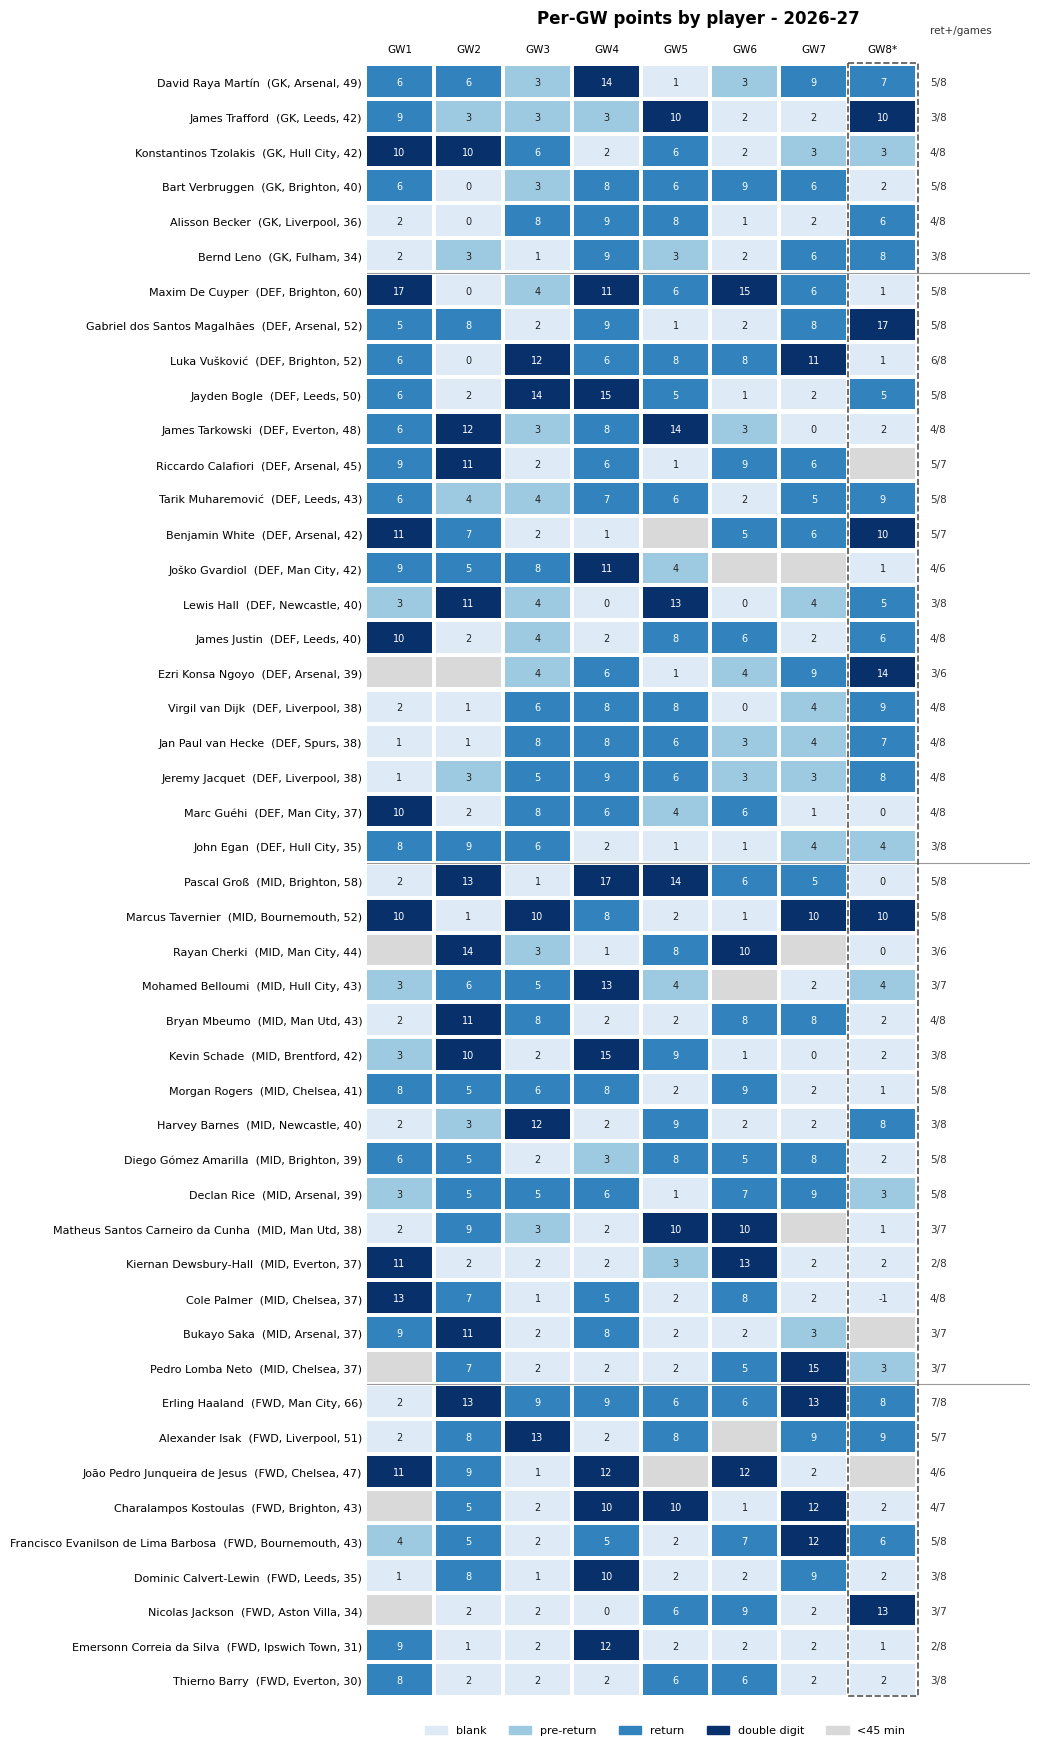

In [35]:
from matplotlib.colors import ListedColormap, BoundaryNorm

COLORS = {"blank": "#deebf7", "pre-return": "#9ecae1", "return": "#3182bd", "double digit": "#08306b"}
DNP = "#d9d9d9"
R = len(ROUNDS)
gw_idx = gw.set_index(["name", "round"])

def tile(name, rnd):
    try:
        r = gw_idx.loc[(name, rnd)]
    except KeyError:
        return None
    if not COUNT_NONPLAYING and r["minutes"] < MIN_MINUTES:
        return None
    return int(r["total_points"])

d = uni.copy()
fig_w = max(6, 0.55 * R) + 4.5
fig, ax = plt.subplots(figsize=(fig_w, 0.34 * len(d) + 1.6))
for i, name in enumerate(d["name"]):
    for j, rnd in enumerate(ROUNDS):
        pts = tile(name, rnd)
        col = DNP if pts is None else COLORS[to_bucket(pts)]
        ax.add_patch(plt.Rectangle((j, i), 0.94, 0.88, color=col, lw=0))
        if pts is not None:
            ax.text(j + 0.47, i + 0.46, str(pts), ha="center", va="center", fontsize=7,
                    color="white" if to_bucket(pts) in ("return", "double digit") else "#222")
    ax.text(R + 0.15, i + 0.46, f"{tab.loc[i, 'ret+']}/{tab.loc[i, 'played']}",
            va="center", fontsize=7.5, color="#333")

ax.set_xlim(0, R + 1.6); ax.set_ylim(len(d), -0.2)
ax.set_xticks([j + 0.47 for j in range(R)])
ax.set_xticklabels([f"GW{r}{'*' if r in PROV_ROUNDS else ''}" for r in ROUNDS], fontsize=7.5)
ax.xaxis.tick_top()
ax.set_yticks([i + 0.46 for i in range(len(d))])
ax.set_yticklabels([f"{n}  ({p}, {t}, {int(pt)})"
                    for n, p, t, pt in zip(d["name"], d["position"], d["team"], d["total_points"])],
                   fontsize=8)
ax.text(R + 0.15, -0.9, "ret+/games", fontsize=7.5, color="#333", va="bottom")
for j, rnd in enumerate(ROUNDS):
    if rnd in PROV_ROUNDS:
        ax.add_patch(plt.Rectangle((j - 0.04, -0.1), 1.02, len(d) + 0.0, fill=False,
                                   ls="--", edgecolor="#555", lw=1.2, zorder=6))
for b in np.cumsum(d["position"].value_counts().reindex(list(order)).dropna().astype(int))[:-1]:
    ax.axhline(b - 0.06, color="black", lw=0.8, alpha=0.4)
ax.tick_params(length=0); ax.spines[:].set_visible(False)
ax.set_title(f"Per-GW points by player - {SEASON}", fontsize=12, weight="bold", pad=26)

legend = [Patch(color=COLORS[b], label=b) for b in BUCKET_NAMES] + [Patch(color=DNP, label=f"<{MIN_MINUTES} min")]
ax.legend(handles=legend, ncol=5, loc="upper center", bbox_to_anchor=(0.45, -0.01),
          fontsize=8, frameon=False)
plt.tight_layout(); plt.show()

## GW × position — how good was each week for the league?
Share of counted players of each position who reached a **return** (≥ the return threshold)
that week. This is the context the tile strip needs: a 5 in a week where only 10% of MIDs
returned is worth more than a 5 in a week where 40% did. `*` = provisional GW.

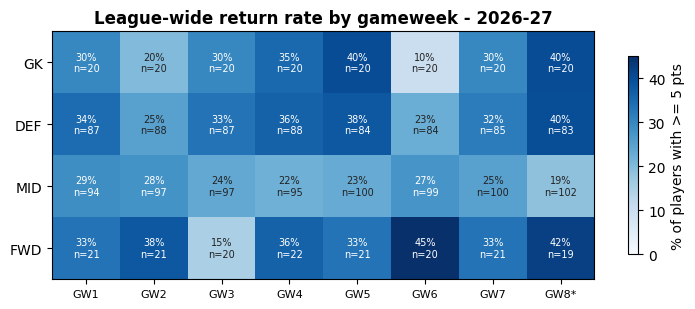

In [36]:
RET_LO = BUCKETS[2][1]
g = (rows.assign(ret=rows["total_points"] >= RET_LO)
         .groupby(["position", "round"])["ret"].agg(["mean", "size"]))
POS_ORDER = ["GK", "DEF", "MID", "FWD"]
M = g["mean"].unstack("round").reindex(POS_ORDER) * 100
N = g["size"].unstack("round").reindex(POS_ORDER)

fig, ax = plt.subplots(figsize=(max(6, 0.7 * R) + 1.5, 3.2))
im = ax.imshow(M.values, aspect="auto", cmap="Blues", vmin=0)
ax.set_xticks(range(R)); ax.set_xticklabels([f"GW{r}{'*' if r in PROV_ROUNDS else ''}" for r in M.columns], fontsize=8)
ax.set_yticks(range(len(POS_ORDER))); ax.set_yticklabels(POS_ORDER)
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        v = M.values[i, j]
        ax.text(j, i, f"{v:.0f}%\nn={int(N.values[i, j])}", ha="center", va="center", fontsize=7,
                color="white" if v > 0.6 * np.nanmax(M.values) else "#222")
fig.colorbar(im, ax=ax, label=f"% of players with >= {RET_LO} pts", shrink=0.8)
ax.set_title(f"League-wide return rate by gameweek - {SEASON}", fontsize=12, weight="bold")
plt.tight_layout(); plt.show()

## Boom-or-bust scatter — the bridge to #07
Each player by **blank share** (x) vs **double-digit share** (y); bubble area ∝ total points.
Points are jittered slightly because shares sit on a coarse grid (multiples of 1/n). The **×**
markers are each position's baseline (the average player), and the dotted cross-hair is the
all-position baseline, so the quadrants read relative to the field: top-left = hauls often,
blanks rarely; bottom-right = rarely explodes, often blanks. Only standouts are labelled.

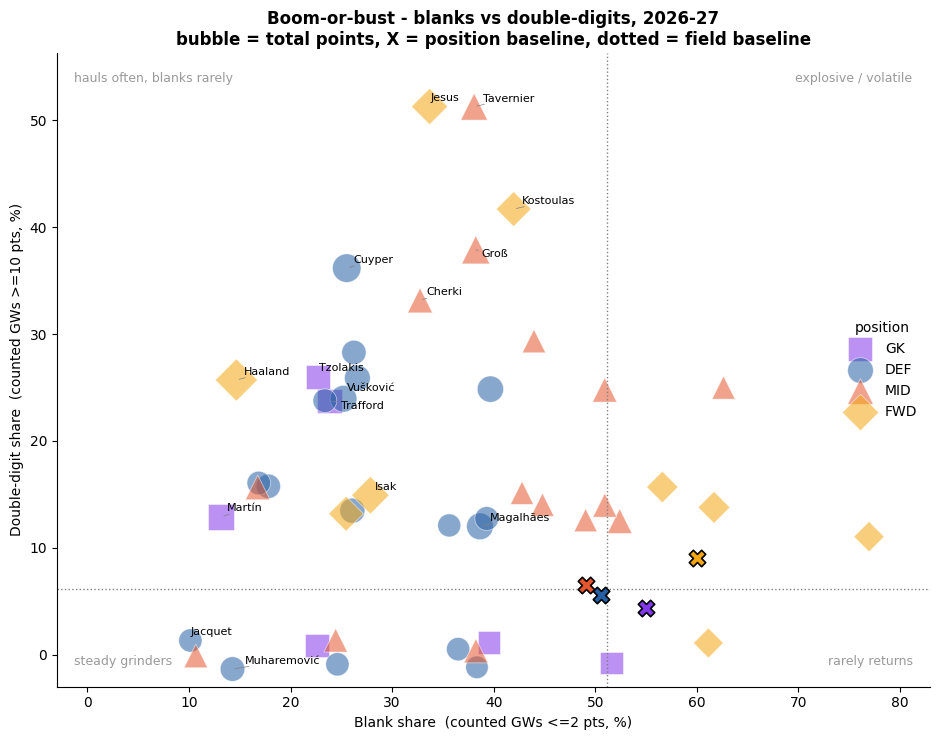

In [37]:
d = uni.copy()
d["blank_share"] = d["blank"] / d["played"] * 100
d["dd_share"] = d["double digit"] / d["played"] * 100
MARKER = {"GK": "s", "DEF": "o", "MID": "^", "FWD": "D"}
POS_COLOR = {"GK": "#8338ec", "DEF": "#2660a4", "MID": "#e4572e", "FWD": "#f3a712"}

rng = np.random.default_rng(0)
jx = rng.uniform(-2.5, 2.5, len(d)); jy = rng.uniform(-1.5, 1.5, len(d))
d["x"] = d["blank_share"] + jx; d["y"] = d["dd_share"] + jy
d["size"] = 40 + 420 * (d["total_points"] / d["total_points"].max())

fig, ax = plt.subplots(figsize=(9.5, 7.5))
for p in POS_ORDER:
    s = d[d["position"] == p]
    if len(s):
        ax.scatter(s["x"], s["y"], s=s["size"], color=POS_COLOR[p], alpha=0.55, marker=MARKER[p],
                   label=p, edgecolor="white", linewidth=0.6)
    ax.scatter(base.loc[p, "blank"], base.loc[p, "double digit"], marker="X", s=140,
               color=POS_COLOR[p], edgecolor="black", linewidth=1.2, zorder=5)

all_bl = rows["bucket"].eq("blank").mean() * 100
all_dd = rows["bucket"].eq("double digit").mean() * 100
ax.axvline(all_bl, color="grey", ls=":", lw=1); ax.axhline(all_dd, color="grey", ls=":", lw=1)

# label standouts only: top-3 by points per position + extremes on either axis
lab = set(d.groupby("position")["total_points"].nlargest(3).index.get_level_values(1))
lab |= set(d.nlargest(3, "dd_share").index) | set(d.nsmallest(3, "blank_share").index)
from adjustText import adjust_text
texts = [ax.text(d.loc[i, "x"], d.loc[i, "y"], d.loc[i, "name"].split()[-1], fontsize=8) for i in lab]
adjust_text(texts, ax=ax, arrowprops=dict(arrowstyle="-", color="grey", lw=0.5),
            expand=(1.3, 1.5))

xmax = max(d["x"].max(), base["blank"].max()) + 6
ymax = max(d["y"].max(), base["double digit"].max()) + 5
ax.set_xlim(-3, xmax); ax.set_ylim(-3, ymax)
kw = dict(fontsize=9, color="grey", alpha=0.8, transform=ax.transAxes)
ax.text(0.02, 0.97, "hauls often, blanks rarely", va="top", **kw)
ax.text(0.98, 0.97, "explosive / volatile", va="top", ha="right", **kw)
ax.text(0.02, 0.03, "steady grinders", va="bottom", **kw)
ax.text(0.98, 0.03, "rarely returns", va="bottom", ha="right", **kw)

ax.set_xlabel("Blank share  (counted GWs <=2 pts, %)")
ax.set_ylabel("Double-digit share  (counted GWs >=10 pts, %)")
ax.set_title(f"Boom-or-bust - blanks vs double-digits, {SEASON}\n"
             f"bubble = total points, X = position baseline, dotted = field baseline",
             fontsize=12, weight="bold")
ax.legend(title="position", frameon=False, loc="center right")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

## Who sits in each quadrant?
The cross-hair is the **field baseline** (all counted player-GWs: blank share and double-digit share
across every player, not just the universe). Every player is assigned to one quadrant; the first
table lists members per quadrant (by points), the second is a full player → quadrant lookup.
`↑` = above the baseline on that axis. Ties on the line go to the "better" side (not more blanks,
not fewer double-digits).

In [38]:
def quadrant(r):
    many_blank = r["blank_share"] > all_bl
    many_dd    = r["dd_share"] >= all_dd
    if many_dd and not many_blank: return "hauls often, blanks rarely"
    if many_dd and many_blank:     return "explosive / volatile"
    if not many_dd and not many_blank: return "steady grinders"
    return "rarely returns"

QUAD_ORDER = ["hauls often, blanks rarely", "explosive / volatile", "steady grinders", "rarely returns"]
d["quadrant"] = d.apply(quadrant, axis=1)
d["blank %"] = d["blank_share"].round(0).astype(int)
d["DD %"] = d["dd_share"].round(0).astype(int)

print(f"field baseline: blank {all_bl:.1f}%  |  double-digit {all_dd:.1f}%\n")
summary = (d.sort_values("total_points", ascending=False)
             .groupby("quadrant")
             .apply(lambda g: pd.Series({
                 "n": len(g),
                 "players": ", ".join(f"{n.split()[-1]} ({p})" for n, p in zip(g["name"], g["position"]))}),
                    include_groups=False)
             .reindex(QUAD_ORDER))
pd.set_option("display.max_colwidth", None)
display(summary.style.set_properties(subset=["players"], **{"text-align": "left", "white-space": "normal"}))

lookup = (d.assign(q=d["quadrant"].map({q: i for i, q in enumerate(QUAD_ORDER)}))
            .sort_values(["q", "total_points"], ascending=[True, False])
            [["quadrant", "name", "position", "team", "total_points", "played", "blank", "double digit", "blank %", "DD %"]]
            .rename(columns={"total_points": "pts", "double digit": "DD"}).reset_index(drop=True))
lookup

field baseline: blank 51.2%  |  double-digit 6.2%



,n,players
quadrant,,
"hauls often, blanks rarely",31,"Haaland (FWD), Cuyper (DEF), Groß (MID), Vušković (DEF), Tavernier (MID), Magalhães (DEF), Isak (FWD), Bogle (DEF), Martín (GK), Tarkowski (DEF), Jesus (FWD), Calafiori (DEF), Cherki (MID), Belloumi (MID), Barbosa (FWD), Kostoulas (FWD), Mbeumo (MID), Trafford (GK), Tzolakis (GK), Schade (MID), White (DEF), Gvardiol (DEF), Barnes (MID), Hall (DEF), Justin (DEF), Ngoyo (DEF), Cunha (MID), Neto (MID), Guéhi (DEF), Saka (MID), Palmer (MID)"
explosive / volatile,4,"Dewsbury-Hall (MID), Calvert-Lewin (FWD), Jackson (FWD), Silva (FWD)"
steady grinders,11,"Muharemović (DEF), Rogers (MID), Verbruggen (GK), Rice (MID), Amarilla (MID), Jacquet (DEF), Hecke (DEF), Dijk (DEF), Becker (GK), Egan (DEF), Leno (GK)"
rarely returns,1,Barry (FWD)


,quadrant,name,position,team,pts,played,blank,DD,blank %,DD %
0,"hauls often, blanks rarely",Erling Haaland,FWD,Man City,66,8,1,2,12,25
1,"hauls often, blanks rarely",Maxim De Cuyper,DEF,Brighton,60,8,2,3,25,38
2,"hauls often, blanks rarely",Pascal Groß,MID,Brighton,58,8,3,3,38,38
3,"hauls often, blanks rarely",Gabriel dos Santos Magalhães,DEF,Arsenal,52,8,3,1,38,12
4,"hauls often, blanks rarely",Luka Vušković,DEF,Brighton,52,8,2,2,25,25
5,"hauls often, blanks rarely",Marcus Tavernier,MID,Bournemouth,52,8,3,4,38,50
6,"hauls often, blanks rarely",Alexander Isak,FWD,Liverpool,51,7,2,1,29,14
7,"hauls often, blanks rarely",Jayden Bogle,DEF,Leeds,50,8,3,2,38,25
8,"hauls often, blanks rarely",David Raya Martín,GK,Arsenal,49,8,1,1,12,12
9,"hauls often, blanks rarely",James Tarkowski,DEF,Everton,48,8,2,2,25,25
